In [3]:
import pandas as pd
import joblib

In [4]:
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn.impute import SimpleImputer
from sklearn.pipeline import Pipeline
from sklearn.ensemble import RandomForestClassifier

from sklearn.metrics import (
    accuracy_score,
    classification_report,
    confusion_matrix,
    f1_score
)

# Load the dataset

In [5]:
data_path=r"D:\3rd Sem\Ai\MediGuide-Medical-Symptom-Expert-System\data\raw\diabetes_012_health_indicators_BRFSS2015.csv"
print("data loaded successfully")

data loaded successfully


In [6]:
df=pd.read_csv(data_path)

In [7]:
df.head(5)

,Diabetes_012,HighBP,HighChol,CholCheck,BMI,Smoker,Stroke,HeartDiseaseorAttack,PhysActivity,Fruits,...,AnyHealthcare,NoDocbcCost,GenHlth,MentHlth,PhysHlth,DiffWalk,Sex,Age,Education,Income
0,0.0,1.0,1.0,1.0,40.0,1.0,0.0,0.0,0.0,0.0,...,1.0,0.0,5.0,18.0,15.0,1.0,0.0,9.0,4.0,3.0
1,0.0,0.0,0.0,0.0,25.0,1.0,0.0,0.0,1.0,0.0,...,0.0,1.0,3.0,0.0,0.0,0.0,0.0,7.0,6.0,1.0
2,0.0,1.0,1.0,1.0,28.0,0.0,0.0,0.0,0.0,1.0,...,1.0,1.0,5.0,30.0,30.0,1.0,0.0,9.0,4.0,8.0
3,0.0,1.0,0.0,1.0,27.0,0.0,0.0,0.0,1.0,1.0,...,1.0,0.0,2.0,0.0,0.0,0.0,0.0,11.0,3.0,6.0
4,0.0,1.0,1.0,1.0,24.0,0.0,0.0,0.0,1.0,1.0,...,1.0,0.0,2.0,3.0,0.0,0.0,0.0,11.0,5.0,4.0


In [8]:
shape=df.shape
print("Dataset shape: ",shape)

Dataset shape:  (253680, 22)


# UnderStand the dataset

In [9]:
df.columns.tolist()

['Diabetes_012',
 'HighBP',
 'HighChol',
 'CholCheck',
 'BMI',
 'Smoker',
 'Stroke',
 'HeartDiseaseorAttack',
 'PhysActivity',
 'Fruits',
 'Veggies',
 'HvyAlcoholConsump',
 'AnyHealthcare',
 'NoDocbcCost',
 'GenHlth',
 'MentHlth',
 'PhysHlth',
 'DiffWalk',
 'Sex',
 'Age',
 'Education',
 'Income']

In [10]:
df.dtypes

Diabetes_012            float64
HighBP                  float64
HighChol                float64
CholCheck               float64
BMI                     float64
Smoker                  float64
Stroke                  float64
HeartDiseaseorAttack    float64
PhysActivity            float64
Fruits                  float64
Veggies                 float64
HvyAlcoholConsump       float64
AnyHealthcare           float64
NoDocbcCost             float64
GenHlth                 float64
MentHlth                float64
PhysHlth                float64
DiffWalk                float64
Sex                     float64
Age                     float64
Education               float64
Income                  float64
dtype: object

In [11]:
df.tail(5)

,Diabetes_012,HighBP,HighChol,CholCheck,BMI,Smoker,Stroke,HeartDiseaseorAttack,PhysActivity,Fruits,...,AnyHealthcare,NoDocbcCost,GenHlth,MentHlth,PhysHlth,DiffWalk,Sex,Age,Education,Income
253675,0.0,1.0,1.0,1.0,45.0,0.0,0.0,0.0,0.0,1.0,...,1.0,0.0,3.0,0.0,5.0,0.0,1.0,5.0,6.0,7.0
253676,2.0,1.0,1.0,1.0,18.0,0.0,0.0,0.0,0.0,0.0,...,1.0,0.0,4.0,0.0,0.0,1.0,0.0,11.0,2.0,4.0
253677,0.0,0.0,0.0,1.0,28.0,0.0,0.0,0.0,1.0,1.0,...,1.0,0.0,1.0,0.0,0.0,0.0,0.0,2.0,5.0,2.0
253678,0.0,1.0,0.0,1.0,23.0,0.0,0.0,0.0,0.0,1.0,...,1.0,0.0,3.0,0.0,0.0,0.0,1.0,7.0,5.0,1.0
253679,2.0,1.0,1.0,1.0,25.0,0.0,0.0,1.0,1.0,1.0,...,1.0,0.0,2.0,0.0,0.0,0.0,0.0,9.0,6.0,2.0


In [14]:
missing_values=df.isna().sum()
print("\nMissing values Percentage: ",(missing_values/len(df))*100)


Missing values Percentage:  Diabetes_012            0.0
HighBP                  0.0
HighChol                0.0
CholCheck               0.0
BMI                     0.0
Smoker                  0.0
Stroke                  0.0
HeartDiseaseorAttack    0.0
PhysActivity            0.0
Fruits                  0.0
Veggies                 0.0
HvyAlcoholConsump       0.0
AnyHealthcare           0.0
NoDocbcCost             0.0
GenHlth                 0.0
MentHlth                0.0
PhysHlth                0.0
DiffWalk                0.0
Sex                     0.0
Age                     0.0
Education               0.0
Income                  0.0
dtype: float64


In [15]:
duplicate_count=df.duplicated().sum()
print("Duplicate rows: ",duplicate_count)

Duplicate rows:  23899


In [9]:
print("Dataset information: ")
df.info()

Dataset information: 
<class 'pandas.DataFrame'>
RangeIndex: 253680 entries, 0 to 253679
Data columns (total 22 columns):
 #   Column                Non-Null Count   Dtype  
---  ------                --------------   -----  
 0   Diabetes_012          253680 non-null  float64
 1   HighBP                253680 non-null  float64
 2   HighChol              253680 non-null  float64
 3   CholCheck             253680 non-null  float64
 4   BMI                   253680 non-null  float64
 5   Smoker                253680 non-null  float64
 6   Stroke                253680 non-null  float64
 7   HeartDiseaseorAttack  253680 non-null  float64
 8   PhysActivity          253680 non-null  float64
 9   Fruits                253680 non-null  float64
 10  Veggies               253680 non-null  float64
 11  HvyAlcoholConsump     253680 non-null  float64
 12  AnyHealthcare         253680 non-null  float64
 13  NoDocbcCost           253680 non-null  float64
 14  GenHlth               253680 non-null  fl

In [13]:
print("\nStatistical Summary: ")
df.describe().T


Statistical Summary: 


,count,mean,std,min,25%,50%,75%,max
Diabetes_012,253680.0,0.296921,0.698160,0.0,0.0,0.0,0.0,2.0
HighBP,253680.0,0.429001,0.494934,0.0,0.0,0.0,1.0,1.0
HighChol,253680.0,0.424121,0.494210,0.0,0.0,0.0,1.0,1.0
CholCheck,253680.0,0.962670,0.189571,0.0,1.0,1.0,1.0,1.0
BMI,253680.0,28.382364,6.608694,12.0,24.0,27.0,31.0,98.0
Smoker,253680.0,0.443169,0.496761,0.0,0.0,0.0,1.0,1.0
Stroke,253680.0,0.040571,0.197294,0.0,0.0,0.0,0.0,1.0
HeartDiseaseorAttack,253680.0,0.094186,0.292087,0.0,0.0,0.0,0.0,1.0
PhysActivity,253680.0,0.756544,0.429169,0.0,1.0,1.0,1.0,1.0
Fruits,253680.0,0.634256,0.481639,0.0,0.0,1.0,1.0,1.0


# clean columns name and convert data types

In [16]:
df.columns=df.columns.str.strip()


In [17]:
for column in df.columns:
    df[column]=pd.to_numeric(
        df[column],errors="coerce"
    )

df=df.replace([np.inf ,-np.inf],np.nan) 

print("Data types after conversion:")
display(df.dtypes.to_frame("Data type"))

Data types after conversion:


,Data type
Diabetes_012,float64
HighBP,float64
HighChol,float64
CholCheck,float64
BMI,float64
Smoker,float64
Stroke,float64
HeartDiseaseorAttack,float64
PhysActivity,float64
Fruits,float64


In [18]:
target="Diabetes_012"

In [19]:
if target not in df.columns:
    raise ValueError(f"target column {target} not found")



In [20]:
before=len(df)
df=df.dropna(subset=[target]).copy()

print("Rows removed:" ,before-len(df))
print("Remaining rows:" ,len(df))

Rows removed: 0
Remaining rows: 253680


# binary columns

In [21]:
binary_columns = [
    "HighBP",
    "HighChol",
    "CholCheck",
    "Smoker",
    "Stroke",
    "HeartDiseaseorAttack",
    "PhysActivity",
    "Fruits",
    "Veggies",
    "HvyAlcoholConsump",
    "AnyHealthcare",
    "NoDocbcCost",
    "DiffWalk",
    "Sex"
]

for column in binary_columns:
    if column in df.columns:
        invalid = ~df[column].isin([0, 1])
        df.loc[invalid, column] = np.nan

print("Binary column validation completed.")

Binary column validation completed.


In [22]:
valid_ranges = {
    "BMI": (1, 100),
    "GenHlth": (1, 5),
    "MentHlth": (0, 30),
    "PhysHlth": (0, 30),
    "Age": (1, 13),
    "Education": (1, 6),
    "Income": (1, 8)
}

In [ ]:
for column, (low, high) in valid_ranges.items():
    if column in df.columns:
        invalid = ~df[column].between(low, high)
        df.loc[invalid, column] = np.nan

print("Range validation completed")

Range validation completed.


In [24]:
print(df[target].value_counts(dropna=False).sort_index())

df=df[df[target].isin([0,1,2])].copy()

df[target]=df[target].astype(int)

print(df[target].value_counts().sort_index())

Diabetes_012
0.0    213703
1.0      4631
2.0     35346
Name: count, dtype: int64
Diabetes_012
0    213703
1      4631
2     35346
Name: count, dtype: int64


# Remove duplicates rows

In [25]:
before = len(df)
df=df.drop_duplicates().reset_index(drop=True)
duplicates_removed =before-len(df)

print("Duplicates removed: ",duplicates_removed)
print(df.shape)

Duplicates removed:  23899
(229781, 22)


# Check missing values after cleaning

In [26]:
display(
    df.isnull().sum().sort_values(
        ascending=False
    ).to_frame("Missing values")
)

print("total missing feature values: ",df.drop(columns=[target]).isnull().sum().sum())

,Missing values
Diabetes_012,0
HighBP,0
HighChol,0
CholCheck,0
BMI,0
Smoker,0
Stroke,0
HeartDiseaseorAttack,0
PhysActivity,0
Fruits,0


total missing feature values:  0


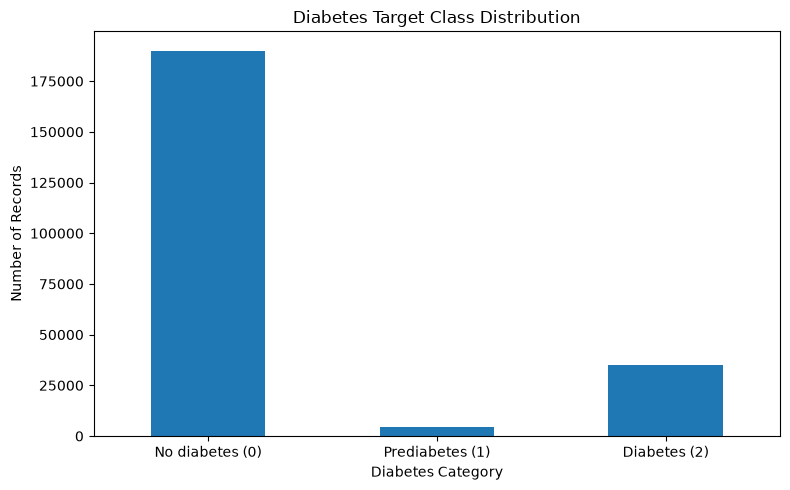

In [28]:
target_counts = df[target].value_counts().sort_index()

target_counts.index = [
    "No diabetes (0)",
    "Prediabetes (1)",
    "Diabetes (2)"
]

plt.figure(figsize=(8, 5))

target_counts.plot(kind="bar")

plt.title("Diabetes Target Class Distribution")
plt.xlabel("Diabetes Category")
plt.ylabel("Number of Records")
plt.xticks(rotation=0)

plt.tight_layout()
plt.show()

In [30]:
df.shape


(229781, 22)

In [33]:
import os
OUTPUT_DIR = "data/processed1"
MODEL_DIR = "model"

os.makedirs(OUTPUT_DIR, exist_ok=True)
os.makedirs(MODEL_DIR, exist_ok=True)


print("Output folders are ready.")

Output folders are ready.


In [34]:
cleaned_file = os.path.join(
    OUTPUT_DIR,
    "diabetes_cleaned.csv"
)
df.to_csv(cleaned_file, index=False)
print("Cleaned dataset saved to:", cleaned_file)

Cleaned dataset saved to: data/processed1\diabetes_cleaned.csv
